#  Analyse bivariée et multivariée

##  Contexte et objectifs

Cette étape consiste à étudier les relations statistiques entre les variables du dataset MetroPT-3.

L'analyse s'appuie sur deux approches complémentaires :

- L'approche statistique : corrélations, dépendances, associations et différences entre groupes.
- L'approche industrielle : interprétation des relations à partir de la documentation technique des capteurs.

Les objectifs sont d'identifier les relations entre les capteurs, les éventuelles redondances entre variables et les différences de comportement associées aux événements de fuite d'air documentés.

Les résultats permettront de préparer les futures étapes de feature engineering, de sélection des variables et de modélisation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import yaml

from scipy.stats import (
    pearsonr,
    spearmanr,
    mannwhitneyu,
    chi2_contingency
)

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [3]:
# Chargement de la configuration
with open("../config.yaml", "r", encoding="utf-8") as fichier:
    config = yaml.safe_load(fichier)

# Chargement du dataset
chemin_dataset = (
    Path("../")
    / config["data"]["processed_path"]
    / config["data"]["processed_dataset_name"]
)

df = pd.read_csv(chemin_dataset)

# Conversion des colonnes
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["event_id"] = df["event_id"].astype("Int64")

# Récupération des variables
variables_numeriques = config["features"]["numeric"]
variables_digitales = config["features"]["categorical"]

cible = config["target"]["name"]

# Dossier des figures
DOSSIER_FIGURES = Path("../") / config["artefacts"]["figures_dir"]
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

print("Dataset chargé avec succès.")
print("Dimensions :", df.shape)
print("Variables numériques :", len(variables_numeriques))
print("Variables digitales :", len(variables_digitales))
print("Variable cible :", cible)

Dataset chargé avec succès.
Dimensions : (1516948, 19)
Variables numériques : 7
Variables digitales : 8
Variable cible : target_event


In [4]:
# Vérification des variables attendues
assert set(variables_numeriques).issubset(df.columns)
assert set(variables_digitales).issubset(df.columns)
assert cible in df.columns

# Vérification de la cible
assert df[cible].isin([0, 1]).all()

# Vérification des valeurs manquantes
print("Valeurs manquantes dans les variables numériques :")
display(df[variables_numeriques].isna().sum())

print("Valeurs manquantes dans les variables digitales :")
display(df[variables_digitales].isna().sum())

print("Valeurs manquantes dans la cible :")
print(df[cible].isna().sum())

print("\nDistribution de la cible :")
display(df[cible].value_counts())

Valeurs manquantes dans les variables numériques :


TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
dtype: int64

Valeurs manquantes dans les variables digitales :


COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64

Valeurs manquantes dans la cible :
0

Distribution de la cible :


target_event
0    1486994
1      29954
Name: count, dtype: int64

##  Analyse bivariée

### Relation entre TP3 et Reservoirs

Selon la documentation technique, la pression mesurée en aval des réservoirs (Reservoirs) devrait être proche de la pression mesurée au niveau du panneau pneumatique (TP3).

Cette analyse vise à vérifier cette relation à travers une approche graphique et statistique.

In [5]:
# Extraction des deux variables
df_tp3_reservoirs = df[["TP3", "Reservoirs"]].copy()

# Vérification
display(df_tp3_reservoirs.describe())

print(
    "Nombre d'observations :",
    len(df_tp3_reservoirs)
)

,TP3,Reservoirs
count,1516948.0000,1516948.0000
mean,8.9846,8.9852
std,0.6391,0.6383
min,0.7300,0.7120
25%,8.4920,8.4940
50%,8.9600,8.9600
75%,9.4920,9.4920
max,10.3020,10.3000


Nombre d'observations : 1516948


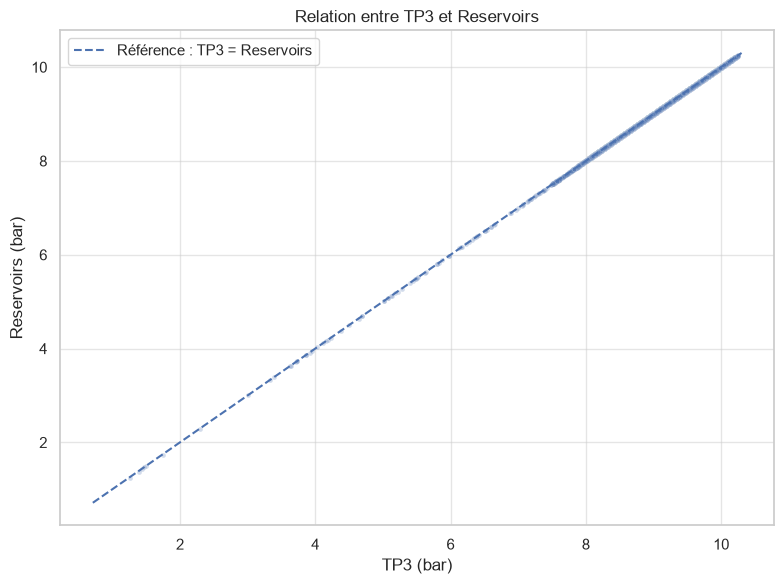

Figure enregistrée : ..\reports\figures\05_tp3_reservoirs_scatter.png


In [6]:
# Échantillonnage pour la visualisation uniquement
df_echantillon = df_tp3_reservoirs.sample(
    n=30000,
    random_state=42
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=df_echantillon,
    x="TP3",
    y="Reservoirs",
    alpha=0.25,
    s=12,
    ax=ax
)

# Droite de référence y = x
limites = [
    min(df_tp3_reservoirs.min()),
    max(df_tp3_reservoirs.max())
]

ax.plot(
    limites,
    limites,
    linestyle="--",
    label="Référence : TP3 = Reservoirs"
)

ax.set_title("Relation entre TP3 et Reservoirs")
ax.set_xlabel("TP3 (bar)")
ax.set_ylabel("Reservoirs (bar)")
ax.legend()

plt.tight_layout()

chemin_figure = DOSSIER_FIGURES / "05_tp3_reservoirs_scatter.png"

plt.savefig(
    chemin_figure,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Figure enregistrée :", chemin_figure)

In [7]:
# Corrélation de Pearson
pearson_corr = df_tp3_reservoirs["TP3"].corr(
    df_tp3_reservoirs["Reservoirs"],
    method="pearson"
)

# Corrélation de Spearman
spearman_corr = df_tp3_reservoirs["TP3"].corr(
    df_tp3_reservoirs["Reservoirs"],
    method="spearman"
)

print(f"Corrélation de Pearson : {pearson_corr:.6f}")
print(f"Corrélation de Spearman : {spearman_corr:.6f}")

Corrélation de Pearson : 0.999993
Corrélation de Spearman : 0.999992


In [8]:
# Différence entre les deux pressions
difference = (
    df_tp3_reservoirs["TP3"]
    - df_tp3_reservoirs["Reservoirs"]
)

resume_difference = difference.describe()

print("Statistiques de TP3 - Reservoirs :")
display(resume_difference)

print(
    "\nDifférence absolue moyenne :",
    difference.abs().mean()
)

Statistiques de TP3 - Reservoirs :


count   1516948.0000
mean         -0.0006
std           0.0025
min          -0.1820
25%          -0.0020
50%           0.0000
75%           0.0000
max           0.0280
dtype: float64


Différence absolue moyenne : 0.0018621020628261512


In [9]:
# Calcul de la différence absolue
difference_absolue = (df["TP3"] - df["Reservoirs"]).abs()

# Quantiles des différences absolues
print("Quantiles des différences absolues :")
display(
    difference_absolue.quantile(
        [0.50, 0.90, 0.95, 0.99, 0.999, 1.00]
    )
)

# Nombre et proportion de différences dépassant certains seuils
seuils = [0.01, 0.05, 0.10]

for seuil in seuils:
    nombre = (difference_absolue > seuil).sum()
    proportion = nombre / len(df) * 100

    print(
        f"Écart > {seuil:.2f} bar : "
        f"{nombre:,} observations ({proportion:.4f} %)"
    )

Quantiles des différences absolues :


0.5000   0.0020
0.9000   0.0040
0.9500   0.0040
0.9900   0.0060
0.9990   0.0100
1.0000   0.1820
dtype: float64

Écart > 0.01 bar : 513 observations (0.0338 %)
Écart > 0.05 bar : 7 observations (0.0005 %)
Écart > 0.10 bar : 3 observations (0.0002 %)


In [10]:
# Calcul de la différence signée et absolue
df_analyse = df[
    ["timestamp", "TP3", "Reservoirs", "target_event", "event_id"]
].copy()

df_analyse["difference"] = (
    df_analyse["TP3"] - df_analyse["Reservoirs"]
)

df_analyse["difference_absolue"] = (
    df_analyse["difference"].abs()
)

# Afficher les 10 écarts les plus importants
observations_extremes = df_analyse.nlargest(
    10, "difference_absolue"
)

display(observations_extremes)

,timestamp,TP3,Reservoirs,target_event,event_id,difference,difference_absolue
480511,2020-04-06 10:02:19,4.7280,4.9100,0,<NA>,-0.1820,0.1820
298768,2020-03-12 11:59:34,8.2960,8.4660,0,<NA>,-0.1700,0.1700
756736,2020-05-16 23:25:44,6.6060,6.7680,0,<NA>,-0.1620,0.1620
298796,2020-03-12 12:04:12,6.2940,6.3860,0,<NA>,-0.0920,0.0920
1124862,2020-07-07 11:15:09,5.9940,6.0640,0,<NA>,-0.0700,0.0700
481290,2020-04-06 14:20:38,9.8160,9.8860,0,<NA>,-0.0700,0.0700
298798,2020-03-12 12:04:32,1.9580,2.0200,0,<NA>,-0.0620,0.0620
299795,2020-03-12 15:43:18,9.4420,9.4840,0,<NA>,-0.0420,0.0420
298802,2020-03-12 12:05:11,2.2880,2.2600,0,<NA>,0.0280,0.0280
298801,2020-03-12 12:05:01,1.8880,1.8600,0,<NA>,0.0280,0.0280


In [11]:
# Indices des 3 écarts absolus les plus importants
indices_extremes = observations_extremes.head(3).index

# Affichage des observations environnantes
for indice in indices_extremes:
    print(f"\nObservation centrale : {indice}")

    debut = max(0, indice - 5)
    fin = min(len(df), indice + 6)

    display(
        df.loc[debut:fin, [
            "timestamp",
            "TP3",
            "Reservoirs",
            "target_event",
            "event_id"
        ]].assign(
            difference=lambda x: x["TP3"] - x["Reservoirs"]
        )
    )


Observation centrale : 480511


,timestamp,TP3,Reservoirs,target_event,event_id,difference
480506,2020-04-06 10:01:29,8.1740,8.1740,0,<NA>,0.0000
480507,2020-04-06 10:01:39,8.1660,8.1640,0,<NA>,0.0020
480508,2020-04-06 10:01:49,8.1580,8.1580,0,<NA>,0.0000
480509,2020-04-06 10:01:59,8.1480,8.1500,0,<NA>,-0.0020
480510,2020-04-06 10:02:09,8.1400,8.1400,0,<NA>,0.0000
480511,2020-04-06 10:02:19,4.7280,4.9100,0,<NA>,-0.1820
480512,2020-04-06 10:02:28,3.6340,3.6280,0,<NA>,0.0060
480513,2020-04-06 10:02:38,3.9840,3.9760,0,<NA>,0.0080
480514,2020-04-06 10:02:48,4.2860,4.2760,0,<NA>,0.0100
480515,2020-04-06 10:02:58,4.4800,4.4680,0,<NA>,0.0120



Observation centrale : 298768


,timestamp,TP3,Reservoirs,target_event,event_id,difference
298763,2020-03-12 11:58:45,9.0060,9.0080,0,<NA>,-0.0020
298764,2020-03-12 11:58:55,8.9840,8.9880,0,<NA>,-0.0040
298765,2020-03-12 11:59:05,8.9640,8.9680,0,<NA>,-0.0040
298766,2020-03-12 11:59:15,8.9440,8.9460,0,<NA>,-0.0020
298767,2020-03-12 11:59:24,8.9240,8.9280,0,<NA>,-0.0040
298768,2020-03-12 11:59:34,8.2960,8.4660,0,<NA>,-0.1700
298769,2020-03-12 11:59:44,7.7340,7.7400,0,<NA>,-0.0060
298770,2020-03-12 11:59:54,7.9360,7.9420,0,<NA>,-0.0060
298771,2020-03-12 12:00:04,8.2080,8.2100,0,<NA>,-0.0020
298772,2020-03-12 12:00:14,8.4340,8.4360,0,<NA>,-0.0020



Observation centrale : 756736


,timestamp,TP3,Reservoirs,target_event,event_id,difference
756731,2020-05-16 23:24:55,8.0840,8.0860,0,<NA>,-0.0020
756732,2020-05-16 23:25:05,8.0760,8.0760,0,<NA>,0.0000
756733,2020-05-16 23:25:14,8.0640,8.0660,0,<NA>,-0.0020
756734,2020-05-16 23:25:24,8.0520,8.0520,0,<NA>,0.0000
756735,2020-05-16 23:25:34,8.0760,8.0760,0,<NA>,0.0000
756736,2020-05-16 23:25:44,6.6060,6.7680,0,<NA>,-0.1620
756737,2020-05-16 23:25:54,3.5220,3.5220,0,<NA>,0.0000
756738,2020-05-16 23:26:04,3.8820,3.8760,0,<NA>,0.0060
756739,2020-05-16 23:26:14,4.1740,4.1640,0,<NA>,0.0100
756740,2020-05-16 23:26:24,4.4360,4.4240,0,<NA>,0.0120


L'analyse de TP3 et Reservoirs révèle une relation linéaire et monotone quasi parfaite (Pearson = 0,999993 ; Spearman = 0,999992). La différence absolue moyenne est de 0,00186 bar et 99 % des observations présentent un écart inférieur ou égal à 0,006 bar. Les écarts extrêmes identifiés sont ponctuels et ne montrent pas de divergence persistante dans les observations environnantes. Ces résultats confirment une forte redondance informationnelle globale entre les deux variables. Leur éventuelle suppression sera étudiée ultérieurement, en tenant compte de leur intérêt industriel et de leur comportement dans les différents états de fonctionnement.

In [12]:
# Tableau croisé COMP / MPG
table_comp_mpg = pd.crosstab(
    df["COMP"],
    df["MPG"],
    margins=True
)

display(table_comp_mpg)

MPG,0.0000,1.0000,All
COMP,,,
0.0000,247328,0,247328
1.0000,6512,1263108,1269620
All,253840,1263108,1516948


In [13]:
# Proportion d'observations où COMP et MPG ont la même valeur
concordance = (df["COMP"] == df["MPG"]).mean() * 100

# Proportion d'observations où les valeurs sont différentes
discordance = 100 - concordance

print(f"Concordance : {concordance:.4f} %")
print(f"Discordance : {discordance:.4f} %")

Concordance : 99.5707 %
Discordance : 0.4293 %


In [14]:
# Extraire les observations discordantes
df_discordances = df.loc[
    df["COMP"] != df["MPG"],
    ["timestamp", "COMP", "MPG", "target_event", "event_id"]
].copy()

print("Nombre de discordances :", len(df_discordances))

# Répartition des discordances par mois
df_discordances["mois"] = (
    pd.to_datetime(df_discordances["timestamp"]).dt.to_period("M")
)

print("\nRépartition mensuelle :")
display(
    df_discordances["mois"]
    .value_counts()
    .sort_index()
)

# Répartition par cible
print("\nRépartition selon la cible :")
display(
    pd.crosstab(
        df_discordances["target_event"],
        df_discordances["COMP"].astype(str) + " / " +
        df_discordances["MPG"].astype(str)
    )
)

Nombre de discordances : 6512

Répartition mensuelle :


mois
2020-03     119
2020-04    4885
2020-05       1
2020-06       6
2020-07    1501
Freq: M, Name: count, dtype: int64


Répartition selon la cible :


col_0,1.0 / 0.0
target_event,
0,6512


In [15]:
# Identifier les observations discordantes
discordant = df["COMP"] != df["MPG"]

# Identifier les séquences consécutives
groupes = (discordant != discordant.shift()).cumsum()

sequences = (
    df.loc[discordant]
    .assign(groupe=groupes[discordant].values)
    .groupby("groupe")
    .agg(
        date_debut=("timestamp", "first"),
        date_fin=("timestamp", "last"),
        nombre_observations=("timestamp", "size")
    )
)

sequences["duree"] = (
    pd.to_datetime(sequences["date_fin"])
    - pd.to_datetime(sequences["date_debut"])
)

print("Nombre de séquences :", len(sequences))
print("\nStatistiques des séquences :")

display(sequences["nombre_observations"].describe())

print("\nLes 15 séquences les plus longues :")

display(
    sequences.sort_values(
        "nombre_observations",
        ascending=False
    ).head(15)
)

Nombre de séquences : 1429

Statistiques des séquences :


count   1429.0000
mean       4.5570
std        1.1421
min        1.0000
25%        4.0000
50%        4.0000
75%        5.0000
max       15.0000
Name: nombre_observations, dtype: float64


Les 15 séquences les plus longues :


,date_debut,date_fin,nombre_observations,duree
groupe,,,,
2206,2020-07-22 06:44:34,2020-07-22 06:46:59,15,0 days 00:02:25
66,2020-04-20 04:50:46,2020-04-20 04:53:02,14,0 days 00:02:16
2858,2020-07-22 13:02:13,2020-07-22 13:04:24,12,0 days 00:02:11
1912,2020-04-20 22:32:46,2020-04-20 22:34:46,11,0 days 00:02:00
2426,2020-07-22 08:52:31,2020-07-22 08:54:19,10,0 days 00:01:48
952,2020-04-20 13:18:59,2020-04-20 13:20:46,10,0 days 00:01:47
2090,2020-04-21 00:19:09,2020-04-21 00:20:32,8,0 days 00:01:23
2762,2020-07-22 12:05:46,2020-07-22 12:07:09,8,0 days 00:01:23
2148,2020-04-21 00:51:32,2020-04-21 00:52:55,8,0 days 00:01:23


In [16]:
# Ajouter les groupes aux observations discordantes
df_temp = df.loc[discordant, ["timestamp"]].copy()
df_temp["groupe"] = groupes.loc[discordant]

# Calculer les écarts temporels entre observations d'une même séquence
df_temp["timestamp"] = pd.to_datetime(df_temp["timestamp"])

df_temp["intervalle_secondes"] = (
    df_temp.groupby("groupe")["timestamp"]
    .diff()
    .dt.total_seconds()
)

# Statistiques des intervalles
print("Intervalles temporels entre observations discordantes :")

display(
    df_temp["intervalle_secondes"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

print(
    "\nNombre d'intervalles supérieurs à 30 secondes :",
    (df_temp["intervalle_secondes"] > 30).sum()
)

Intervalles temporels entre observations discordantes :


count   5083.0000
mean      11.8879
std        0.3379
min        9.0000
50%       12.0000
90%       12.0000
95%       12.0000
99%       12.0000
max       14.0000
Name: intervalle_secondes, dtype: float64


Nombre d'intervalles supérieurs à 30 secondes : 0


L'étude de la relation entre COMP et MPG révèle une concordance de 99,5707 %. Les 6 512 observations discordantes (0,4293 %) correspondent exclusivement à la configuration COMP = 1 et MPG = 0. Elles sont réparties en 1 429 séquences temporelles, avec une durée généralement courte et des intervalles réguliers, dont la moyenne est de 11,89 secondes. Toutes ces discordances appartiennent à la classe 0 de la cible documentée. Les deux variables présentent donc une forte redondance informationnelle, sans être parfaitement équivalentes. Elles sont conservées à ce stade pour évaluer ultérieurement leur contribution respective au modèle.

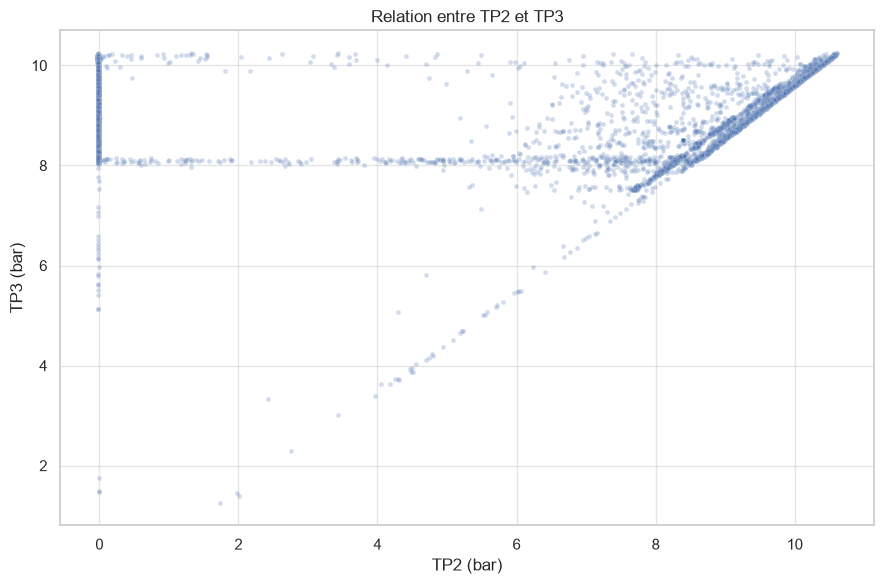

Corrélation de Pearson : -0.011161
Corrélation de Spearman : 0.004374


In [17]:
# Échantillon pour visualisation
echantillon = df.sample(
    n=30000,
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=echantillon,
    x="TP2",
    y="TP3",
    alpha=0.25,
    s=12
)

plt.title("Relation entre TP2 et TP3")
plt.xlabel("TP2 (bar)")
plt.ylabel("TP3 (bar)")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_tp2_tp3_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Corrélations globales
pearson = df["TP2"].corr(df["TP3"], method="pearson")
spearman = df["TP2"].corr(df["TP3"], method="spearman")

print(f"Corrélation de Pearson : {pearson:.6f}")
print(f"Corrélation de Spearman : {spearman:.6f}")

In [18]:
# Analyse TP2-TP3 selon les états COMP et DV_eletric

resultats_etats = (
    df.groupby(["COMP", "DV_eletric"], observed=True)
    .apply(
        lambda groupe: pd.Series({
            "nombre_observations": len(groupe),
            "TP2_moyenne": groupe["TP2"].mean(),
            "TP3_moyenne": groupe["TP3"].mean(),
            "Pearson": groupe["TP2"].corr(
                groupe["TP3"], method="pearson"
            ),
            "Spearman": groupe["TP2"].corr(
                groupe["TP3"], method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(resultats_etats)

,COMP,DV_eletric,nombre_observations,TP2_moyenne,TP3_moyenne,Pearson,Spearman
0,0.0000,0.0000,10226.0000,3.0610,8.5895,-0.1255,0.1493
1,0.0000,1.0000,237102.0000,8.6363,8.8456,0.6288,0.8438
2,1.0000,0.0000,1263084.0000,-0.0040,9.0099,0.0681,0.0397
3,1.0000,1.0000,6536.0000,0.1559,9.7550,-0.7968,-0.9683


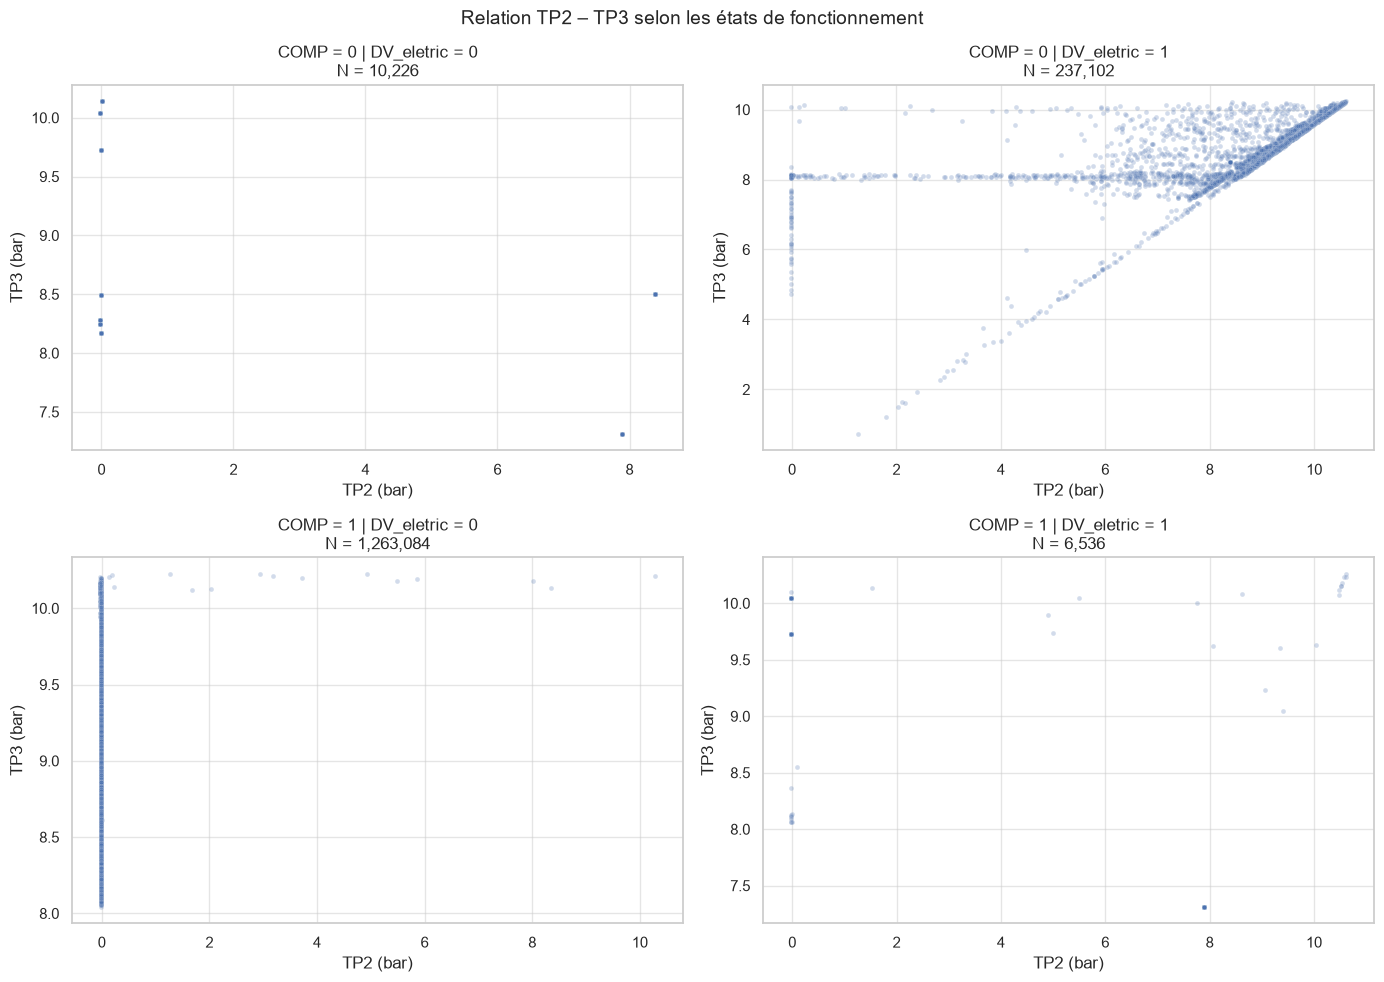

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

configurations = [
    (0, 0),
    (0, 1),
    (1, 0),
    (1, 1)
]

for ax, (comp, dv) in zip(axes.flatten(), configurations):

    sous_groupe = df[
        (df["COMP"] == comp) &
        (df["DV_eletric"] == dv)
    ]

    # Échantillonnage pour lisibilité
    echantillon = sous_groupe.sample(
        n=min(5000, len(sous_groupe)),
        random_state=42
    )

    sns.scatterplot(
        data=echantillon,
        x="TP2",
        y="TP3",
        alpha=0.25,
        s=12,
        ax=ax
    )

    ax.set_title(
        f"COMP = {comp} | DV_eletric = {dv}\n"
        f"N = {len(sous_groupe):,}"
    )

    ax.set_xlabel("TP2 (bar)")
    ax.set_ylabel("TP3 (bar)")

plt.suptitle(
    "Relation TP2 – TP3 selon les états de fonctionnement",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_tp2_tp3_by_operating_state.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Analyse descriptive par configuration
resultats_distribution = []

for (comp, dv), groupe in df.groupby(
    ["COMP", "DV_eletric"],
    observed=True
):
    resultats_distribution.append({
        "COMP": comp,
        "DV_eletric": dv,
        "N": len(groupe),

        "TP2_mediane": groupe["TP2"].median(),
        "TP2_Q25": groupe["TP2"].quantile(0.25),
        "TP2_Q75": groupe["TP2"].quantile(0.75),
        "TP2_n_unique": groupe["TP2"].nunique(),

        "TP3_mediane": groupe["TP3"].median(),
        "TP3_Q25": groupe["TP3"].quantile(0.25),
        "TP3_Q75": groupe["TP3"].quantile(0.75),
        "TP3_n_unique": groupe["TP3"].nunique(),

        "TP2_proche_zero_pct": (
            groupe["TP2"].abs() < 0.05
        ).mean() * 100
    })

resultats_distribution = pd.DataFrame(
    resultats_distribution
)

display(resultats_distribution.round(4))

,COMP,DV_eletric,N,TP2_mediane,TP2_Q25,TP2_Q75,TP2_n_unique,TP3_mediane,TP3_Q25,TP3_Q75,TP3_n_unique,TP2_proche_zero_pct
0,0.0000,0.0000,10226,-0.0100,-0.0140,8.3900,8,8.5060,8.2480,8.5060,9,63.3972
1,0.0000,1.0000,237102,9.0080,8.3100,9.7680,5189,8.8340,8.2780,9.5280,3676,1.4774
2,1.0000,0.0000,1263084,-0.0120,-0.0140,-0.0120,1958,8.9780,8.5120,9.4800,1123,99.7635
3,1.0000,1.0000,6536,-0.0140,-0.0140,-0.0140,29,9.7280,9.7280,9.7280,38,97.8580


In [21]:
groupe = df[
    (df["COMP"] == 0) &
    (df["DV_eletric"] == 0)
]

print("Distribution de TP2 :")
print(groupe["TP2"].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
))

print("\nValeurs les plus fréquentes de TP2 :")
display(groupe["TP2"].value_counts().head(15))

Distribution de TP2 :
count   10226.0000
mean        3.0610
std         4.0462
min        -0.0200
10%        -0.0180
25%        -0.0140
50%        -0.0100
75%         8.3900
90%         8.3900
95%         8.3900
max         8.3900
Name: TP2, dtype: float64

Valeurs les plus fréquentes de TP2 :


TP2
8.3900     3711
-0.0100    3010
-0.0140    1217
-0.0180     910
-0.0160     897
-0.0200     392
0.0040       57
7.8880       32
Name: count, dtype: int64

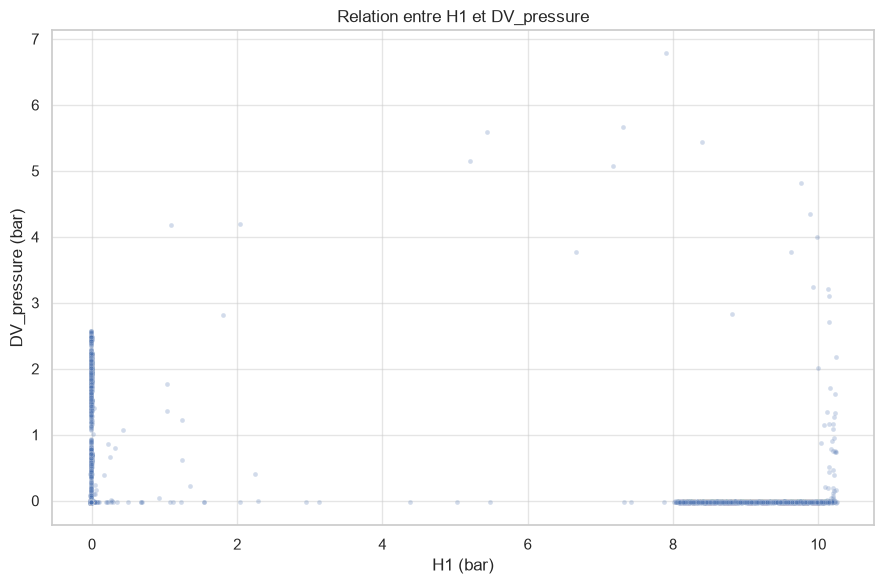

Corrélation de Pearson : -0.425513
Corrélation de Spearman : -0.149464


In [22]:
# Nuage de points H1 - DV_pressure
echantillon = df.sample(
    n=30000,
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=echantillon,
    x="H1",
    y="DV_pressure",
    alpha=0.25,
    s=12
)

plt.title("Relation entre H1 et DV_pressure")
plt.xlabel("H1 (bar)")
plt.ylabel("DV_pressure (bar)")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_h1_dv_pressure_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Corrélations
pearson = df["H1"].corr(
    df["DV_pressure"],
    method="pearson"
)

spearman = df["H1"].corr(
    df["DV_pressure"],
    method="spearman"
)

print(f"Corrélation de Pearson : {pearson:.6f}")
print(f"Corrélation de Spearman : {spearman:.6f}")

In [23]:
# Analyse H1 - DV_pressure selon les états COMP et DV_eletric

resultats_h1 = (
    df.groupby(
        ["COMP", "DV_eletric"],
        observed=True
    )
    .apply(
        lambda groupe: pd.Series({
            "nombre_observations": len(groupe),
            "H1_moyenne": groupe["H1"].mean(),
            "DV_pressure_moyenne": groupe["DV_pressure"].mean(),
            "Pearson": groupe["H1"].corr(
                groupe["DV_pressure"],
                method="pearson"
            ),
            "Spearman": groupe["H1"].corr(
                groupe["DV_pressure"],
                method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(resultats_h1)

,COMP,DV_eletric,nombre_observations,H1_moyenne,DV_pressure_moyenne,Pearson,Spearman
0,0.0000,0.0000,10226.0000,5.4684,-0.0180,-0.7016,-0.7620
1,0.0000,1.0000,237102.0000,0.0062,0.4423,0.0437,0.6061
2,1.0000,0.0000,1263084.0000,8.9942,-0.0156,-0.0431,0.0098
3,1.0000,1.0000,6536.0000,9.5847,-0.0193,-0.0874,0.8525


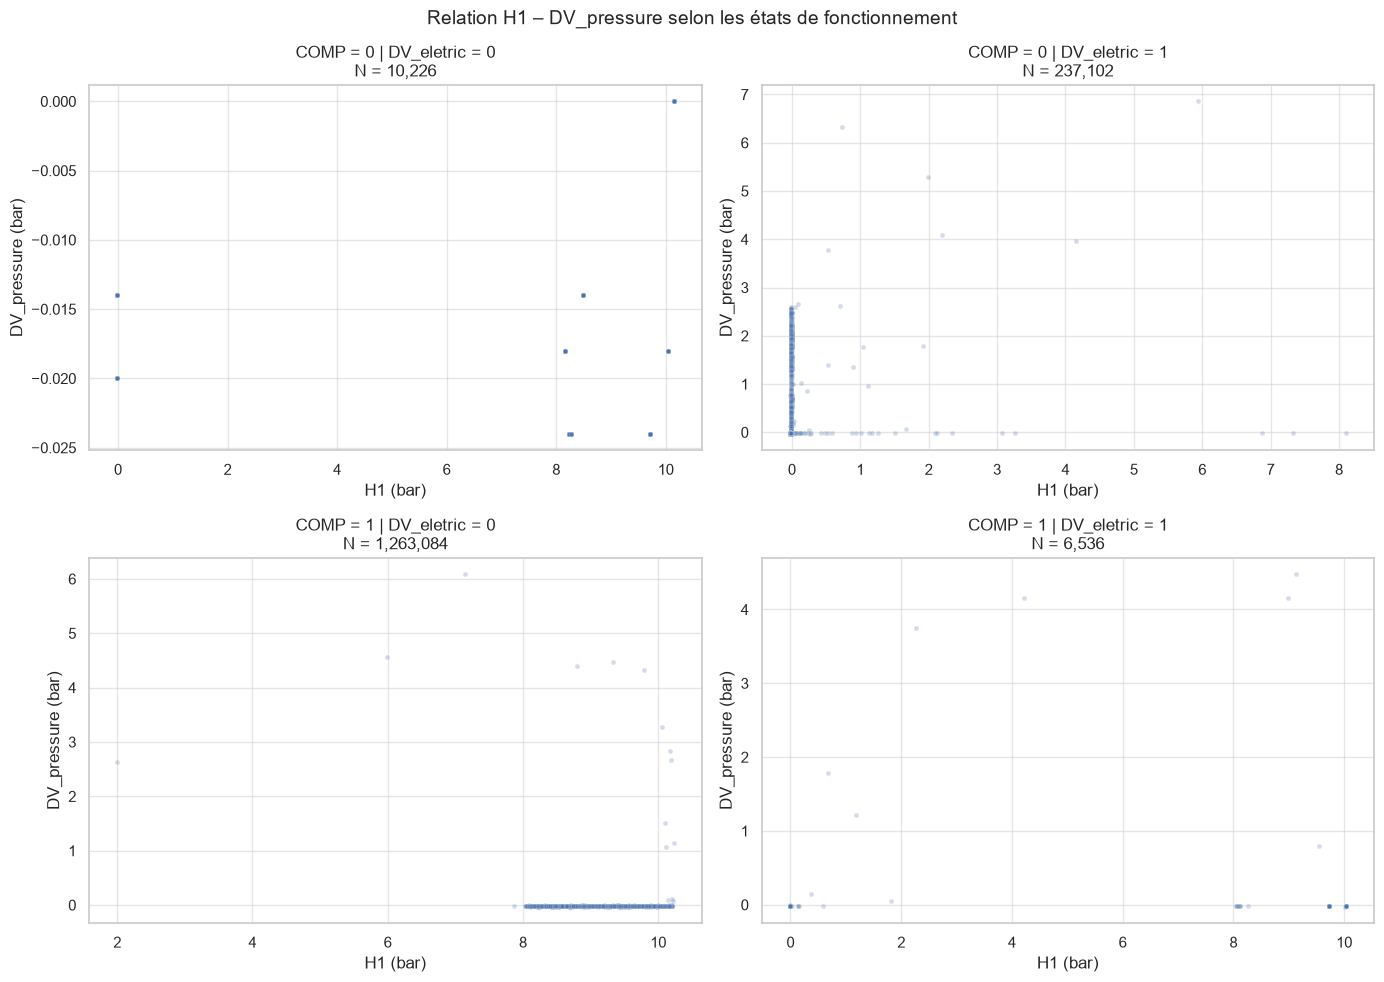

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

configurations = [(0, 0), (0, 1), (1, 0), (1, 1)]

for ax, (comp, dv) in zip(axes.flatten(), configurations):

    sous_groupe = df[
        (df["COMP"] == comp) &
        (df["DV_eletric"] == dv)
    ]

    echantillon = sous_groupe.sample(
        n=min(5000, len(sous_groupe)),
        random_state=42
    )

    sns.scatterplot(
        data=echantillon,
        x="H1",
        y="DV_pressure",
        alpha=0.25,
        s=12,
        ax=ax
    )

    ax.set_title(
        f"COMP = {comp} | DV_eletric = {dv}\n"
        f"N = {len(sous_groupe):,}"
    )

    ax.set_xlabel("H1 (bar)")
    ax.set_ylabel("DV_pressure (bar)")

plt.suptitle(
    "Relation H1 – DV_pressure selon les états de fonctionnement",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_h1_dv_pressure_by_operating_state.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
resultats_h1_distribution = []

for (comp, dv), groupe in df.groupby(
    ["COMP", "DV_eletric"],
    observed=True
):
    resultats_h1_distribution.append({
        "COMP": comp,
        "DV_eletric": dv,
        "N": len(groupe),

        "H1_mediane": groupe["H1"].median(),
        "H1_Q25": groupe["H1"].quantile(0.25),
        "H1_Q75": groupe["H1"].quantile(0.75),
        "H1_n_unique": groupe["H1"].nunique(),
        "H1_proche_zero_pct": (
            groupe["H1"].abs() < 0.05
        ).mean() * 100,

        "DV_mediane": groupe["DV_pressure"].median(),
        "DV_Q25": groupe["DV_pressure"].quantile(0.25),
        "DV_Q75": groupe["DV_pressure"].quantile(0.75),
        "DV_n_unique": groupe["DV_pressure"].nunique(),
        "DV_proche_zero_pct": (
            groupe["DV_pressure"].abs() < 0.05
        ).mean() * 100
    })

resultats_h1_distribution = pd.DataFrame(
    resultats_h1_distribution
)

display(resultats_h1_distribution.round(4))

,COMP,DV_eletric,N,H1_mediane,H1_Q25,H1_Q75,H1_n_unique,H1_proche_zero_pct,DV_mediane,DV_Q25,DV_Q75,DV_n_unique,DV_proche_zero_pct
0,0.0000,0.0000,10226,8.1580,-0.0140,8.2740,9,36.6028,-0.0180,-0.0240,-0.0140,5,100.0000
1,0.0000,1.0000,237102,-0.0120,-0.0140,-0.0080,1233,99.1358,-0.0180,-0.0200,0.6720,1587,71.1862
2,1.0000,0.0000,1263084,8.9640,8.4980,9.4660,1735,0.0046,-0.0200,-0.0220,-0.0180,1636,99.7834
3,1.0000,1.0000,6536,9.7180,9.7180,9.7180,33,1.9431,-0.0240,-0.0240,-0.0200,18,99.8623


In [26]:
for comp, dv in [(0, 0), (1, 1)]:

    groupe = df[
        (df["COMP"] == comp) &
        (df["DV_eletric"] == dv)
    ]

    print(f"\nCOMP={comp} | DV_eletric={dv}")
    print("Nombre d'observations :", len(groupe))

    print("\nValeurs fréquentes de H1 :")
    display(groupe["H1"].value_counts().head(10))

    print("\nValeurs fréquentes de DV_pressure :")
    display(groupe["DV_pressure"].value_counts().head(10))


COMP=0 | DV_eletric=0
Nombre d'observations : 10226

Valeurs fréquentes de H1 :


H1
-0.0140    3711
8.1580     2519
9.7180     1217
8.2380      910
8.2740      897
8.4820      491
10.0360     392
10.1440      57
-0.0100      32
Name: count, dtype: int64


Valeurs fréquentes de DV_pressure :


DV_pressure
-0.0140    4202
-0.0240    3024
-0.0180    2911
0.0000       57
-0.0200      32
Name: count, dtype: int64


COMP=1 | DV_eletric=1
Nombre d'observations : 6536

Valeurs fréquentes de H1 :


H1
9.7180     4883
10.0360    1500
-0.0100     120
-0.0140       3
0.1340        2
8.0560        1
8.0480        1
0.4020        1
9.5500        1
8.0540        1
Name: count, dtype: int64


Valeurs fréquentes de DV_pressure :


DV_pressure
-0.0240    4889
-0.0180    1503
-0.0200     122
-0.0220       7
-0.0120       2
-0.0160       1
0.1480        1
0.7920        1
-0.0260       1
0.1440        1
Name: count, dtype: int64

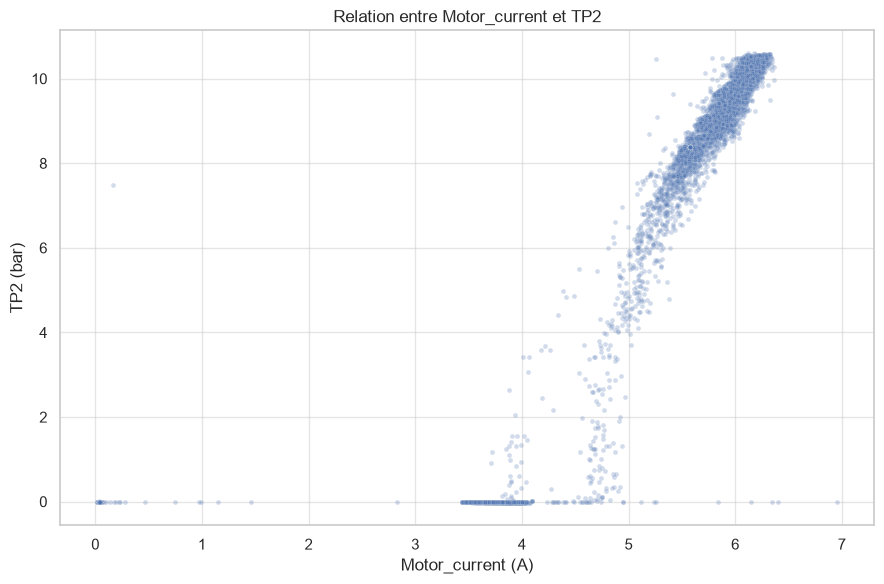

Corrélation de Pearson : 0.697480
Corrélation de Spearman : 0.357963


In [27]:
# Échantillon pour visualisation
echantillon = df.sample(
    n=30000,
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=echantillon,
    x="Motor_current",
    y="TP2",
    alpha=0.25,
    s=12
)

plt.title("Relation entre Motor_current et TP2")
plt.xlabel("Motor_current (A)")
plt.ylabel("TP2 (bar)")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_motor_current_tp2_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Corrélations globales
pearson = df["Motor_current"].corr(
    df["TP2"],
    method="pearson"
)

spearman = df["Motor_current"].corr(
    df["TP2"],
    method="spearman"
)

print(f"Corrélation de Pearson : {pearson:.6f}")
print(f"Corrélation de Spearman : {spearman:.6f}")

In [29]:
# Analyse Motor_current - TP2 selon les états électriques

resultats_motor_tp2 = (
    df.groupby(
        ["COMP", "DV_eletric"],
        observed=True
    )
    .apply(
        lambda groupe: pd.Series({
            "nombre_observations": len(groupe),
            "Motor_current_moyenne": groupe["Motor_current"].mean(),
            "TP2_moyenne": groupe["TP2"].mean(),
            "Pearson": groupe["Motor_current"].corr(
                groupe["TP2"],
                method="pearson"
            ),
            "Spearman": groupe["Motor_current"].corr(
                groupe["TP2"],
                method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(resultats_motor_tp2)

,COMP,DV_eletric,nombre_observations,Motor_current_moyenne,TP2_moyenne,Pearson,Spearman
0,0.0000,0.0000,10226.0000,2.6923,3.0610,0.8531,0.6500
1,0.0000,1.0000,237102.0000,5.7294,8.6363,0.7917,0.9423
2,1.0000,0.0000,1263084.0000,1.3447,-0.0040,0.0751,-0.0807
3,1.0000,1.0000,6536.0000,3.9098,0.1559,0.8139,0.9933


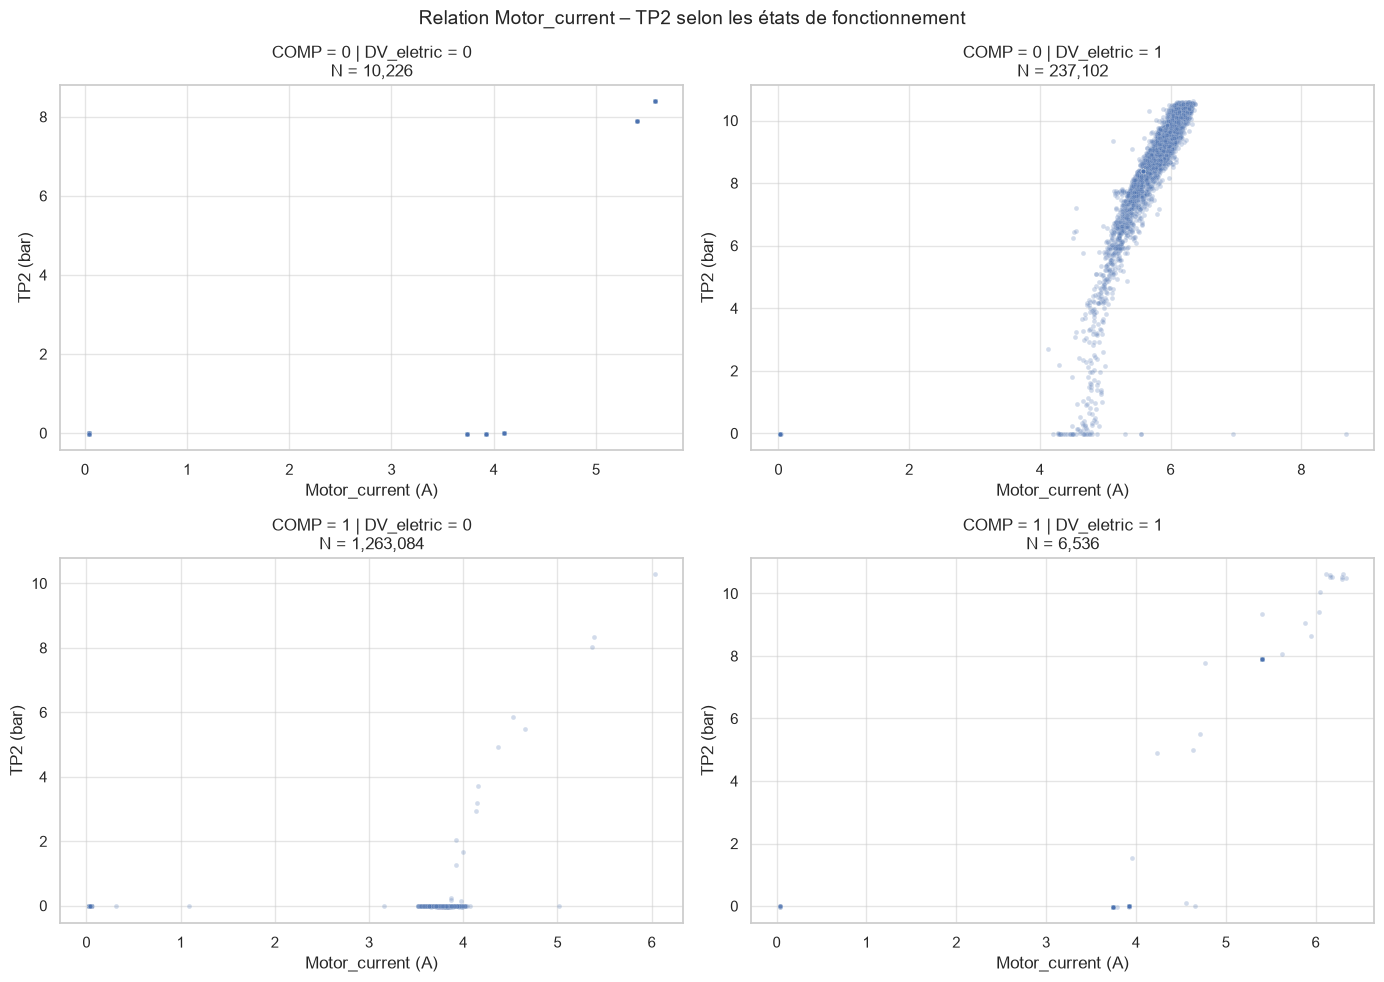

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

configurations = [(0, 0), (0, 1), (1, 0), (1, 1)]

for ax, (comp, dv) in zip(axes.flatten(), configurations):

    sous_groupe = df[
        (df["COMP"] == comp) &
        (df["DV_eletric"] == dv)
    ]

    echantillon = sous_groupe.sample(
        n=min(5000, len(sous_groupe)),
        random_state=42
    )

    sns.scatterplot(
        data=echantillon,
        x="Motor_current",
        y="TP2",
        alpha=0.25,
        s=12,
        ax=ax
    )

    ax.set_title(
        f"COMP = {comp} | DV_eletric = {dv}\n"
        f"N = {len(sous_groupe):,}"
    )

    ax.set_xlabel("Motor_current (A)")
    ax.set_ylabel("TP2 (bar)")

plt.suptitle(
    "Relation Motor_current – TP2 selon les états de fonctionnement",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_motor_current_tp2_by_operating_state.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
resultats_motor_distribution = []

for (comp, dv), groupe in df.groupby(
    ["COMP", "DV_eletric"],
    observed=True
):
    resultats_motor_distribution.append({
        "COMP": comp,
        "DV_eletric": dv,
        "N": len(groupe),

        "Motor_median": groupe["Motor_current"].median(),
        "Motor_Q25": groupe["Motor_current"].quantile(0.25),
        "Motor_Q75": groupe["Motor_current"].quantile(0.75),
        "Motor_n_unique": groupe["Motor_current"].nunique(),
        "Motor_proche_zero_pct": (
            groupe["Motor_current"] < 0.1
        ).mean() * 100,

        "TP2_median": groupe["TP2"].median(),
        "TP2_Q25": groupe["TP2"].quantile(0.25),
        "TP2_Q75": groupe["TP2"].quantile(0.75),
        "TP2_n_unique": groupe["TP2"].nunique(),
        "TP2_proche_zero_pct": (
            groupe["TP2"].abs() < 0.05
        ).mean() * 100
    })

resultats_motor_distribution = pd.DataFrame(
    resultats_motor_distribution
)

display(resultats_motor_distribution.round(4))

,COMP,DV_eletric,N,Motor_median,Motor_Q25,Motor_Q75,Motor_n_unique,Motor_proche_zero_pct,TP2_median,TP2_Q25,TP2_Q75,TP2_n_unique,TP2_proche_zero_pct
0,0.0000,0.0000,10226,3.7425,0.0400,5.5750,8,47.1054,-0.0100,-0.0140,8.3900,8,63.3972
1,0.0000,1.0000,237102,5.8475,5.5750,6.0350,1168,0.8650,9.0080,8.3100,9.7680,5189,1.4774
2,1.0000,0.0000,1263084,0.0425,0.0400,3.7200,1382,65.0470,-0.0120,-0.0140,-0.0120,1958,99.7635
3,1.0000,1.0000,6536,3.9225,3.9225,3.9225,34,0.1224,-0.0140,-0.0140,-0.0140,29,97.8580


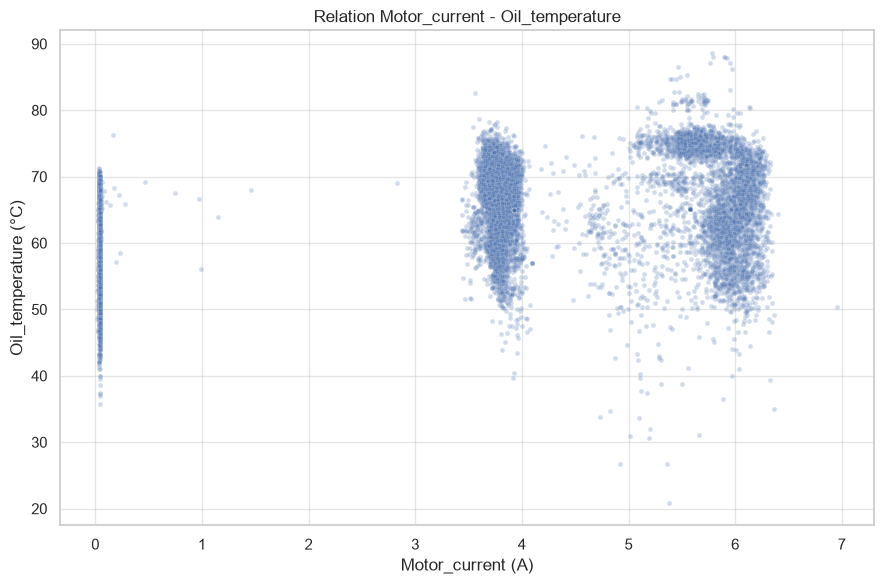

In [32]:
# Échantillon représentatif pour visualisation
echantillon = df.sample(
    n=30000,
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=echantillon,
    x="Motor_current",
    y="Oil_temperature",
    alpha=0.25,
    s=12
)

plt.title("Relation Motor_current - Oil_temperature")
plt.xlabel("Motor_current (A)")
plt.ylabel("Oil_temperature (°C)")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_motor_current_oil_temperature_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
pearson = df["Motor_current"].corr(
    df["Oil_temperature"],
    method="pearson"
)

spearman = df["Motor_current"].corr(
    df["Oil_temperature"],
    method="spearman"
)

print(f"Pearson : {pearson:.6f}")
print(f"Spearman : {spearman:.6f}")

Pearson : 0.528739
Spearman : 0.493669


In [34]:
resultats_motor_temperature = (
    df.groupby(
        ["COMP", "DV_eletric"],
        observed=True
    )
    .apply(
        lambda groupe: pd.Series({
            "N": len(groupe),
            "Motor_median": groupe["Motor_current"].median(),
            "Temperature_median": groupe["Oil_temperature"].median(),
            "Pearson": groupe["Motor_current"].corr(
                groupe["Oil_temperature"],
                method="pearson"
            ),
            "Spearman": groupe["Motor_current"].corr(
                groupe["Oil_temperature"],
                method="spearman"
            )
        }),
        include_groups=False
    )
    .reset_index()
)

display(resultats_motor_temperature)

,COMP,DV_eletric,N,Motor_median,Temperature_median,Pearson,Spearman
0,0.0000,0.0000,10226.0000,3.7425,65.0250,0.4581,0.5686
1,0.0000,1.0000,237102.0000,5.8475,66.1000,0.0711,-0.1884
2,1.0000,0.0000,1263084.0000,0.0425,62.0500,0.6019,0.5230
3,1.0000,1.0000,6536.0000,3.9225,65.0250,-0.1151,-0.8611


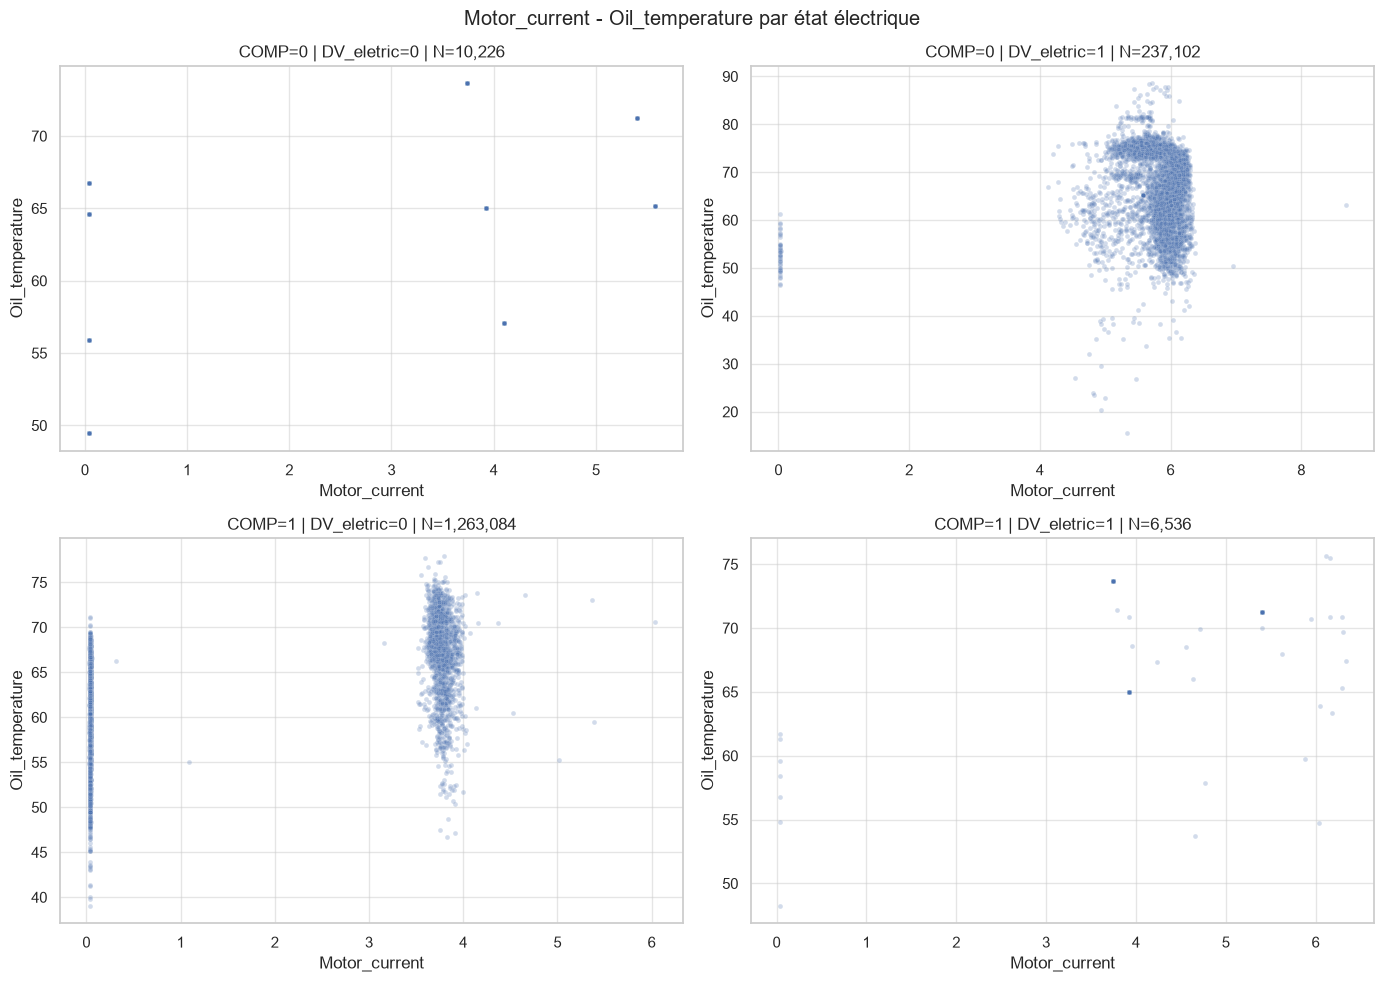

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

configurations = [(0, 0), (0, 1), (1, 0), (1, 1)]

for ax, (comp, dv) in zip(axes.flatten(), configurations):

    groupe = df[
        (df["COMP"] == comp) &
        (df["DV_eletric"] == dv)
    ]

    echantillon = groupe.sample(
        n=min(5000, len(groupe)),
        random_state=42
    )

    sns.scatterplot(
        data=echantillon,
        x="Motor_current",
        y="Oil_temperature",
        alpha=0.25,
        s=12,
        ax=ax
    )

    ax.set_title(
        f"COMP={comp} | DV_eletric={dv} | N={len(groupe):,}"
    )

plt.suptitle("Motor_current - Oil_temperature par état électrique")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_motor_temperature_by_state.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [36]:
correlation_pearson = df[variables_numeriques].corr(
    method="pearson"
)

correlation_spearman = df[variables_numeriques].corr(
    method="spearman"
)

print("Matrice de corrélation Pearson")
display(correlation_pearson.round(3))

print("Matrice de corrélation Spearman")
display(correlation_spearman.round(3))

Matrice de corrélation Pearson


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
TP2,1.0000,-0.0110,-0.9610,0.4150,-0.0120,0.2510,0.6970
TP3,-0.0110,1.0000,0.2250,-0.1530,1.0000,0.4020,0.4140
H1,-0.9610,0.2250,1.0000,-0.4260,0.2260,-0.1620,-0.6000
DV_pressure,0.4150,-0.1530,-0.4260,1.0000,-0.1530,0.3400,0.3020
Reservoirs,-0.0120,1.0000,0.2260,-0.1530,1.0000,0.4020,0.4130
Oil_temperature,0.2510,0.4020,-0.1620,0.3400,0.4020,1.0000,0.5290
Motor_current,0.6970,0.4140,-0.6000,0.3020,0.4130,0.5290,1.0000


Matrice de corrélation Spearman


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
TP2,1.0000,0.0040,-0.3910,0.5500,0.0040,0.3570,0.3580
TP3,0.0040,1.0000,0.7280,-0.0580,1.0000,0.4330,0.4530
H1,-0.3910,0.7280,1.0000,-0.1490,0.7290,0.2530,0.0080
DV_pressure,0.5500,-0.0580,-0.1490,1.0000,-0.0570,0.4380,0.0240
Reservoirs,0.0040,1.0000,0.7290,-0.0570,1.0000,0.4340,0.4520
Oil_temperature,0.3570,0.4330,0.2530,0.4380,0.4340,1.0000,0.4940
Motor_current,0.3580,0.4530,0.0080,0.0240,0.4520,0.4940,1.0000


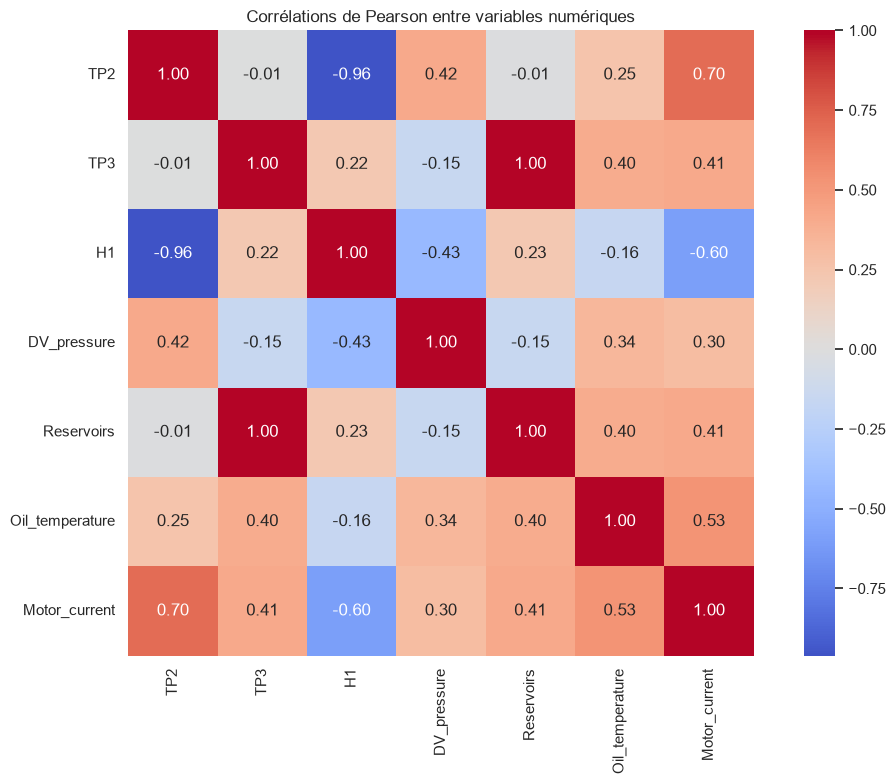

In [37]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Corrélations de Pearson entre variables numériques")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_correlation_pearson.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

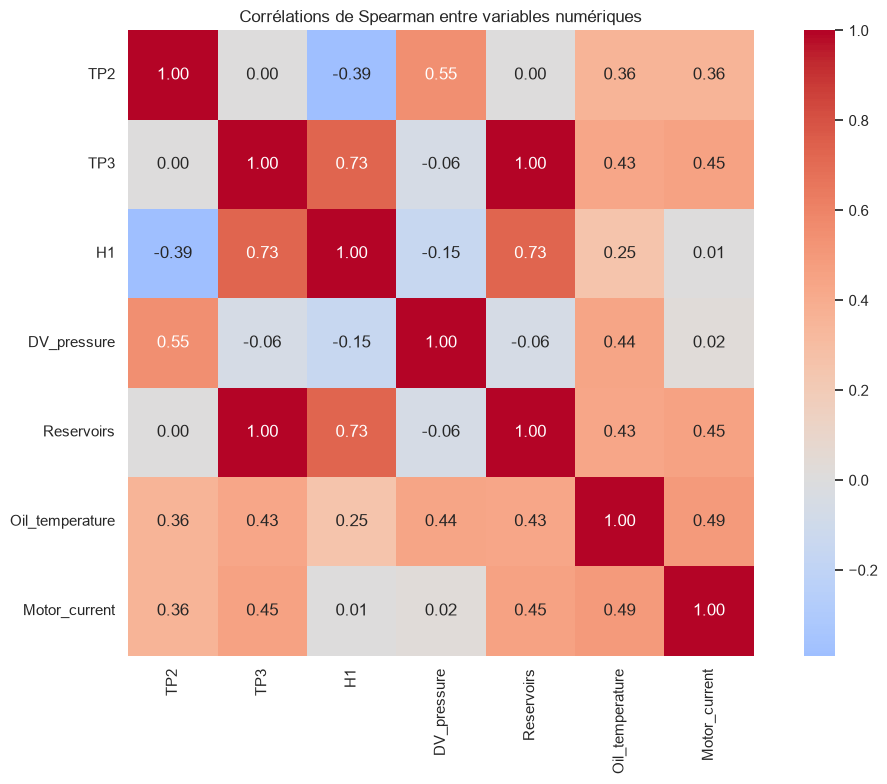

In [38]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Corrélations de Spearman entre variables numériques")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_correlation_spearman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [39]:
paires_fortes = []

for i, variable_1 in enumerate(variables_numeriques):

    for variable_2 in variables_numeriques[i + 1:]:

        pearson = correlation_pearson.loc[
            variable_1, variable_2
        ]

        spearman = correlation_spearman.loc[
            variable_1, variable_2
        ]

        paires_fortes.append({
            "variable_1": variable_1,
            "variable_2": variable_2,
            "Pearson": pearson,
            "Spearman": spearman
        })

df_correlations = pd.DataFrame(paires_fortes)

df_correlations["abs_Pearson"] = (
    df_correlations["Pearson"].abs()
)

df_correlations["abs_Spearman"] = (
    df_correlations["Spearman"].abs()
)

display(
    df_correlations.sort_values(
        "abs_Pearson",
        ascending=False
    )
)

,variable_1,variable_2,Pearson,Spearman,abs_Pearson,abs_Spearman
8,TP3,Reservoirs,1.0000,1.0000,1.0000,1.0000
1,TP2,H1,-0.9613,-0.3907,0.9613,0.3907
5,TP2,Motor_current,0.6975,0.3580,0.6975,0.3580
14,H1,Motor_current,-0.6002,0.0077,0.6002,0.0077
20,Oil_temperature,Motor_current,0.5287,0.4937,0.5287,0.4937
11,H1,DV_pressure,-0.4255,-0.1495,0.4255,0.1495
2,TP2,DV_pressure,0.4150,0.5504,0.4150,0.5504
10,TP3,Motor_current,0.4138,0.4531,0.4138,0.4531
19,Reservoirs,Motor_current,0.4127,0.4520,0.4127,0.4520
18,Reservoirs,Oil_temperature,0.4016,0.4336,0.4016,0.4336


In [40]:
variables_digitales

['COMP',
 'DV_eletric',
 'Towers',
 'MPG',
 'LPS',
 'Pressure_switch',
 'Oil_level',
 'Caudal_impulses']

In [41]:
for variable in variables_digitales:

    print(f"\nVariable : {variable}")

    display(
        df[variable].value_counts(
            normalize=True
        ).mul(100).round(3)
    )


Variable : COMP


COMP
1.0000   83.6960
0.0000   16.3040
Name: proportion, dtype: float64


Variable : DV_eletric


DV_eletric
0.0000   83.9390
1.0000   16.0610
Name: proportion, dtype: float64


Variable : Towers


Towers
1.0000   91.9850
0.0000    8.0150
Name: proportion, dtype: float64

... (6 outputs left out)


Variable : Oil_level


Oil_level
1.0000   90.4160
0.0000    9.5840
Name: proportion, dtype: float64


Variable : Caudal_impulses


Caudal_impulses
1.0000   93.7110
0.0000    6.2890
Name: proportion, dtype: float64

In [42]:
table_comp_mpg = pd.crosstab(
    df["COMP"],
    df["MPG"],
    margins=True
)

display(table_comp_mpg)

MPG,0.0000,1.0000,All
COMP,,,
0.0000,247328,0,247328
1.0000,6512,1263108,1269620
All,253840,1263108,1516948


In [44]:
def calcul_v_cramer(variable_1, variable_2):

    tableau = pd.crosstab(
        df[variable_1],
        df[variable_2]
    )

    chi2, p_value, ddl, attendu = chi2_contingency(
        tableau,
        correction=False
    )

    n = tableau.to_numpy().sum()

    dimension_min = min(
        tableau.shape[0] - 1,
        tableau.shape[1] - 1
    )

    v = np.sqrt(
        chi2 / (n * dimension_min)
    )

    return v

In [45]:
matrice_cramer = pd.DataFrame(
    index=variables_digitales,
    columns=variables_digitales,
    dtype=float
)

for variable_1 in variables_digitales:

    for variable_2 in variables_digitales:

        if variable_1 == variable_2:
            matrice_cramer.loc[
                variable_1, variable_2
            ] = 1.0

        else:
            matrice_cramer.loc[
                variable_1, variable_2
            ] = calcul_v_cramer(
                variable_1,
                variable_2
            )

display(matrice_cramer.round(3))

,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
COMP,1.0000,0.9590,0.6690,0.9850,0.1330,0.1830,0.0180,0.0510
DV_eletric,0.9590,1.0000,0.6070,0.9760,0.1340,0.0140,0.0020,0.0250
Towers,0.6690,0.6070,1.0000,0.6580,0.0920,0.2630,0.0560,0.0870
MPG,0.9850,0.9760,0.6580,1.0000,0.1310,0.1800,0.0530,0.0940
LPS,0.1330,0.1340,0.0920,0.1310,1.0000,0.0040,0.0160,0.0150
Pressure_switch,0.1830,0.0140,0.2630,0.1800,0.0040,1.0000,0.2240,0.2910
Oil_level,0.0180,0.0020,0.0560,0.0530,0.0160,0.2240,1.0000,0.0700
Caudal_impulses,0.0510,0.0250,0.0870,0.0940,0.0150,0.2910,0.0700,1.0000


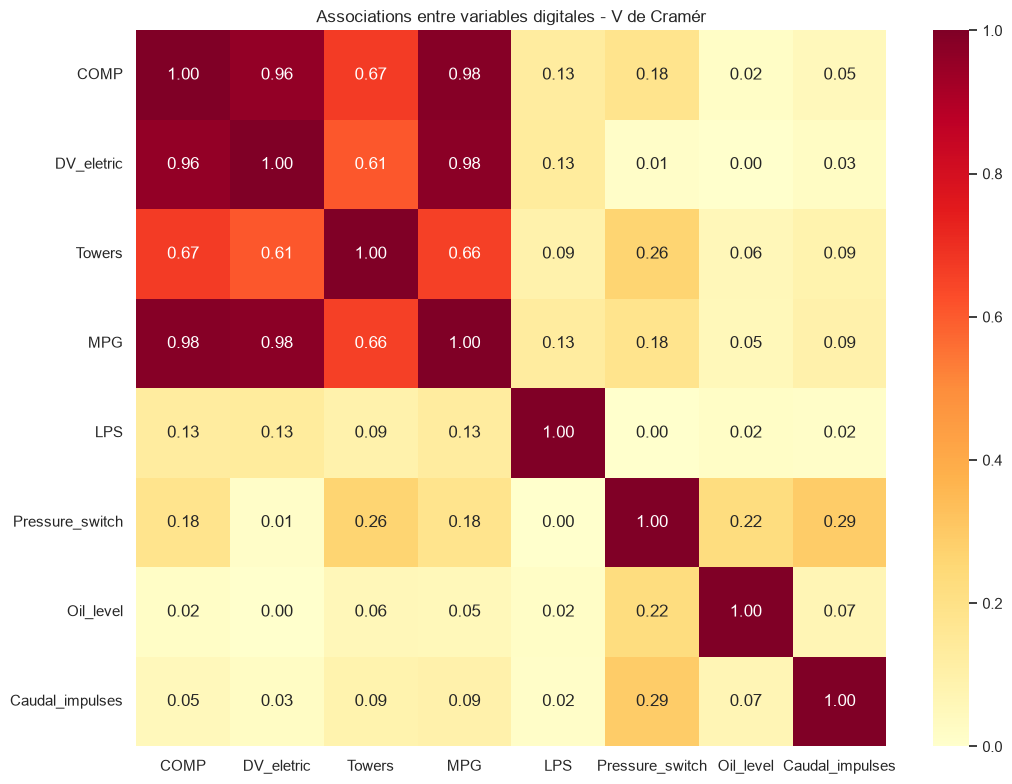

In [46]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    matrice_cramer,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1
)

plt.title("Associations entre variables digitales - V de Cramér")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_cramer_digital.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
associations_digitales = []

for i, variable_1 in enumerate(variables_digitales):

    for variable_2 in variables_digitales[i + 1:]:

        associations_digitales.append({
            "variable_1": variable_1,
            "variable_2": variable_2,
            "V_cramer": matrice_cramer.loc[
                variable_1, variable_2
            ]
        })

df_associations_digitales = pd.DataFrame(
    associations_digitales
)

display(
    df_associations_digitales.sort_values(
        "V_cramer",
        ascending=False
    )
)

,variable_1,variable_2,V_cramer
2,COMP,MPG,0.9846
8,DV_eletric,MPG,0.9756
0,COMP,DV_eletric,0.9593
1,COMP,Towers,0.6688
13,Towers,MPG,0.6585
7,DV_eletric,Towers,0.6072
26,Pressure_switch,Caudal_impulses,0.2913
15,Towers,Pressure_switch,0.2625
25,Pressure_switch,Oil_level,0.2238
4,COMP,Pressure_switch,0.1832


In [48]:
resultats_num_digital = []

for variable_num in variables_numeriques:

    for variable_digital in variables_digitales:

        groupes = df.groupby(
            variable_digital,
            observed=True
        )[variable_num]

        for modalite, valeurs in groupes:

            resultats_num_digital.append({
                "variable_numerique": variable_num,
                "variable_digitale": variable_digital,
                "modalite": modalite,
                "N": len(valeurs),
                "moyenne": valeurs.mean(),
                "mediane": valeurs.median(),
                "Q25": valeurs.quantile(0.25),
                "Q75": valeurs.quantile(0.75),
                "ecart_type": valeurs.std()
            })

df_num_digital = pd.DataFrame(
    resultats_num_digital
)

display(df_num_digital)

,variable_numerique,variable_digitale,modalite,N,moyenne,mediane,Q25,Q75,ecart_type
0,TP2,COMP,0.0000,247328,8.4058,8.9440,8.2220,9.7400,2.3000
1,TP2,COMP,1.0000,1269620,-0.0032,-0.0120,-0.0140,-0.0120,0.2603
2,TP2,DV_eletric,0.0000,1273310,0.0206,-0.0120,-0.0140,-0.0120,0.5164
3,TP2,DV_eletric,1.0000,243638,8.4088,8.9680,8.2040,9.7500,2.3123
4,TP2,Towers,0.0000,121586,8.1564,8.9440,8.0540,9.7420,2.6873
...,...,...,...,...,...,...,...,...,...
107,Motor_current,Pressure_switch,1.0000,1503958,2.0401,0.0450,0.0400,3.8050,2.2976
108,Motor_current,Oil_level,0.0000,145391,2.2820,3.6525,0.0425,3.8575,2.2479
109,Motor_current,Oil_level,1.0000,1371557,2.0256,0.0450,0.0400,3.8050,2.3063
110,Motor_current,Caudal_impulses,0.0000,95406,2.5046,3.7275,0.0400,3.8775,2.2650


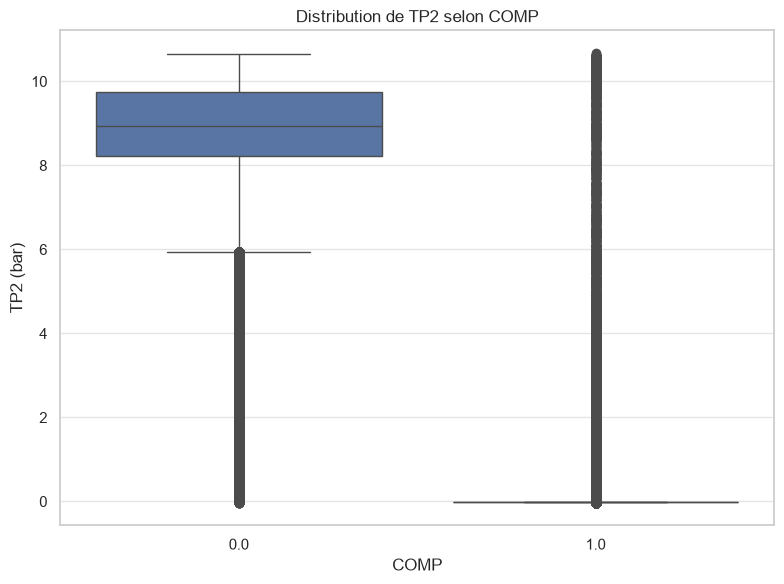

In [49]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="COMP",
    y="TP2"
)

plt.title("Distribution de TP2 selon COMP")
plt.xlabel("COMP")
plt.ylabel("TP2 (bar)")
plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_tp2_by_comp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
def tracer_numerique_digitale(
    variable_numerique,
    variable_digitale
):

    plt.figure(figsize=(8, 6))

    sns.boxplot(
        data=df,
        x=variable_digitale,
        y=variable_numerique
    )

    plt.title(
        f"{variable_numerique} selon {variable_digitale}"
    )

    plt.tight_layout()

    nom_fichier = (
        f"05_{variable_numerique}_by_{variable_digitale}.png"
    )

    plt.savefig(
        DOSSIER_FIGURES / nom_fichier,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

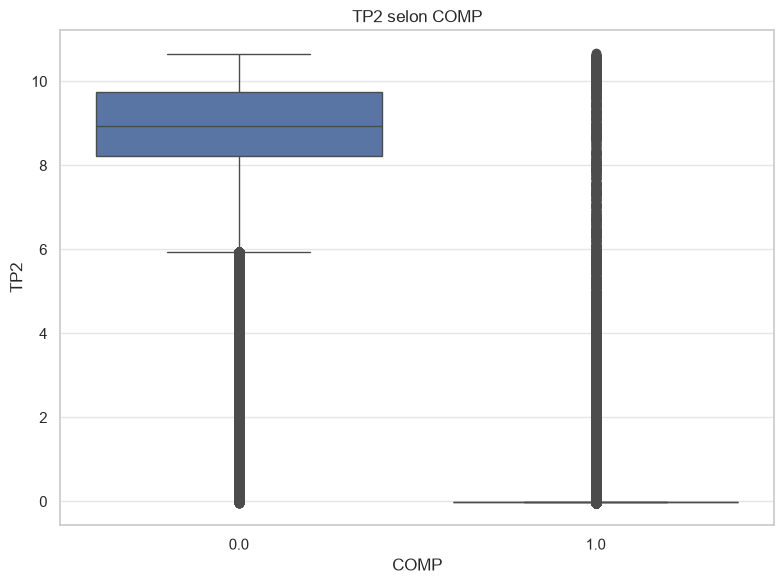

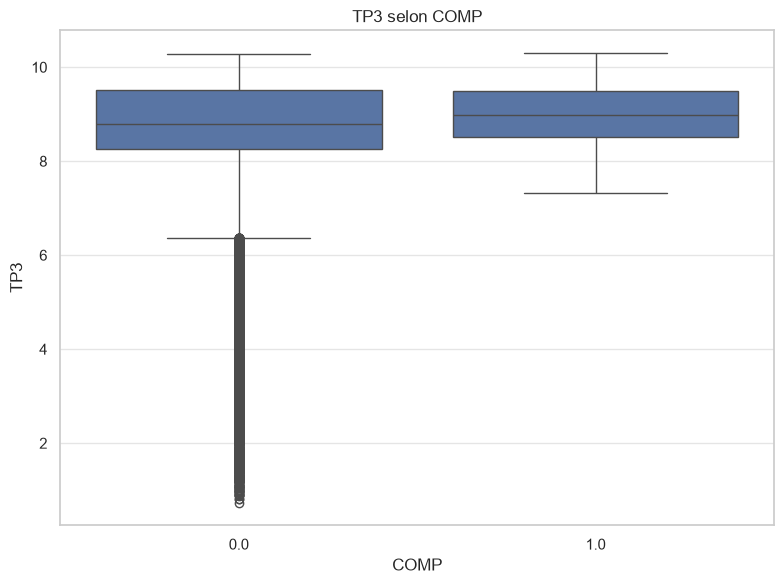

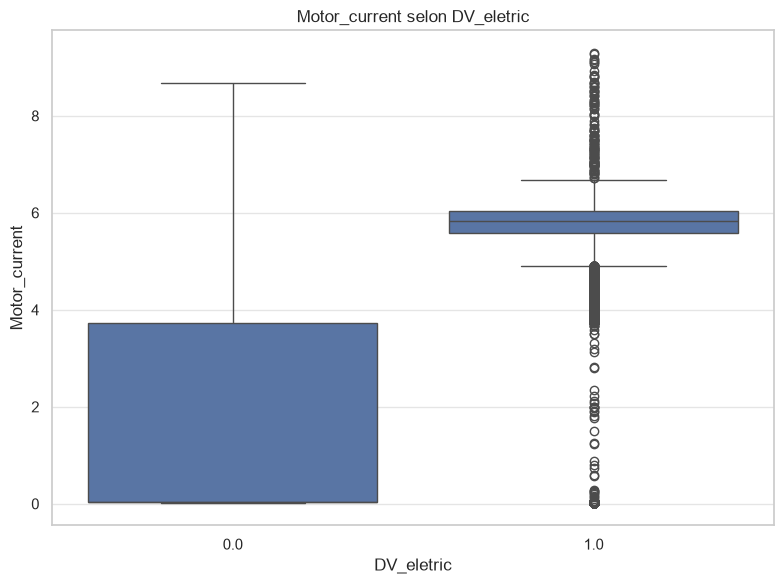

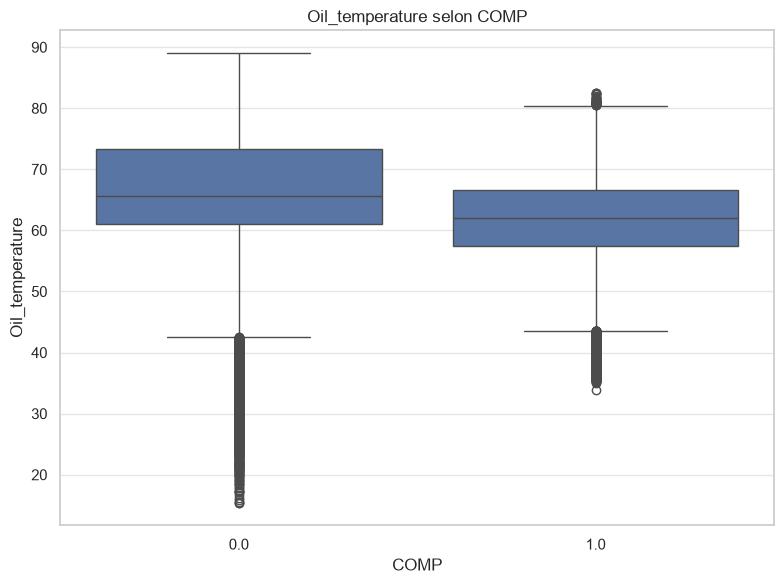

In [51]:
tracer_numerique_digitale("TP2", "COMP")
tracer_numerique_digitale("TP3", "COMP")
tracer_numerique_digitale("Motor_current", "DV_eletric")
tracer_numerique_digitale("Oil_temperature", "COMP")

In [52]:
def taille_effet_rank_biserial(
    variable_numerique,
    variable_digitale
):

    groupe_1 = df.loc[
        df[variable_digitale] == 1,
        variable_numerique
    ].dropna()

    groupe_0 = df.loc[
        df[variable_digitale] == 0,
        variable_numerique
    ].dropna()

    resultat = mannwhitneyu(
        groupe_1,
        groupe_0,
        alternative="two-sided"
    )

    u = resultat.statistic

    delta = (
        2 * u / (len(groupe_1) * len(groupe_0))
    ) - 1

    return {
        "N_0": len(groupe_0),
        "N_1": len(groupe_1),
        "mediane_0": groupe_0.median(),
        "mediane_1": groupe_1.median(),
        "rank_biserial": delta
    }

In [53]:
resultats_effets = []

for variable_num in variables_numeriques:

    for variable_digital in variables_digitales:

        resultat = taille_effet_rank_biserial(
            variable_num,
            variable_digital
        )

        resultat["variable_numerique"] = variable_num
        resultat["variable_digitale"] = variable_digital

        resultats_effets.append(resultat)

df_effets = pd.DataFrame(resultats_effets)

display(
    df_effets.sort_values(
        "rank_biserial",
        key=lambda x: x.abs(),
        ascending=False
    )
)

,N_0,N_1,mediane_0,mediane_1,rank_biserial,variable_numerique,variable_digitale
36,1511760,5188,8.9640,5.7180,-0.9997,Reservoirs,LPS
12,1511760,5188,8.9620,5.7180,-0.9997,TP3,LPS
16,247328,1269620,-0.0120,8.9680,0.9841,H1,COMP
49,1273310,243638,0.0425,5.8350,0.9775,Motor_current,DV_eletric
0,247328,1269620,8.9440,-0.0120,-0.9584,TP2,COMP
48,247328,1269620,5.8275,0.0425,-0.9542,Motor_current,COMP
51,253840,1263108,5.8150,0.0425,-0.9521,Motor_current,MPG
17,1273310,243638,8.9600,-0.0120,-0.9490,H1,DV_eletric
1,1273310,243638,-0.0120,8.9680,0.9427,TP2,DV_eletric
19,253840,1263108,-0.0120,8.9640,0.9397,H1,MPG


In [54]:
resultats_target_numerique = []

for variable in variables_numeriques:

    groupe_0 = df.loc[
        df[cible] == 0,
        variable
    ].dropna()

    groupe_1 = df.loc[
        df[cible] == 1,
        variable
    ].dropna()

    resultats_target_numerique.append({
        "variable": variable,

        "N_classe_0": len(groupe_0),
        "N_classe_1": len(groupe_1),

        "moyenne_0": groupe_0.mean(),
        "moyenne_1": groupe_1.mean(),

        "mediane_0": groupe_0.median(),
        "mediane_1": groupe_1.median(),

        "Q25_0": groupe_0.quantile(0.25),
        "Q75_0": groupe_0.quantile(0.75),

        "Q25_1": groupe_1.quantile(0.25),
        "Q75_1": groupe_1.quantile(0.75)
    })

df_target_numerique = pd.DataFrame(
    resultats_target_numerique
)

display(df_target_numerique.round(4))

,variable,N_classe_0,N_classe_1,moyenne_0,moyenne_1,mediane_0,mediane_1,Q25_0,Q75_0,Q25_1,Q75_1
0,TP2,1486994,29954,1.2319,8.1153,-0.0120,8.2720,-0.0140,-0.0100,7.9600,8.6040
1,TP3,1486994,29954,8.9986,8.2881,8.9780,8.1700,8.5060,9.5020,7.9720,8.7480
2,H1,1486994,29954,7.7198,0.0377,8.8080,-0.0080,8.2780,9.3860,-0.0080,-0.0060
3,DV_pressure,1486994,29954,0.0196,1.8598,-0.0200,2.0120,-0.0220,-0.0180,1.8720,2.1300
4,Reservoirs,1486994,29954,8.9992,8.2895,8.9800,8.1720,8.5060,9.5020,7.9740,8.7500
5,Oil_temperature,1486994,29954,62.3832,75.5984,62.5500,75.4750,57.6750,66.9750,74.7250,76.1750
6,Motor_current,1486994,29954,1.9800,5.5322,0.0450,5.5725,0.0400,3.7950,5.4725,5.6700


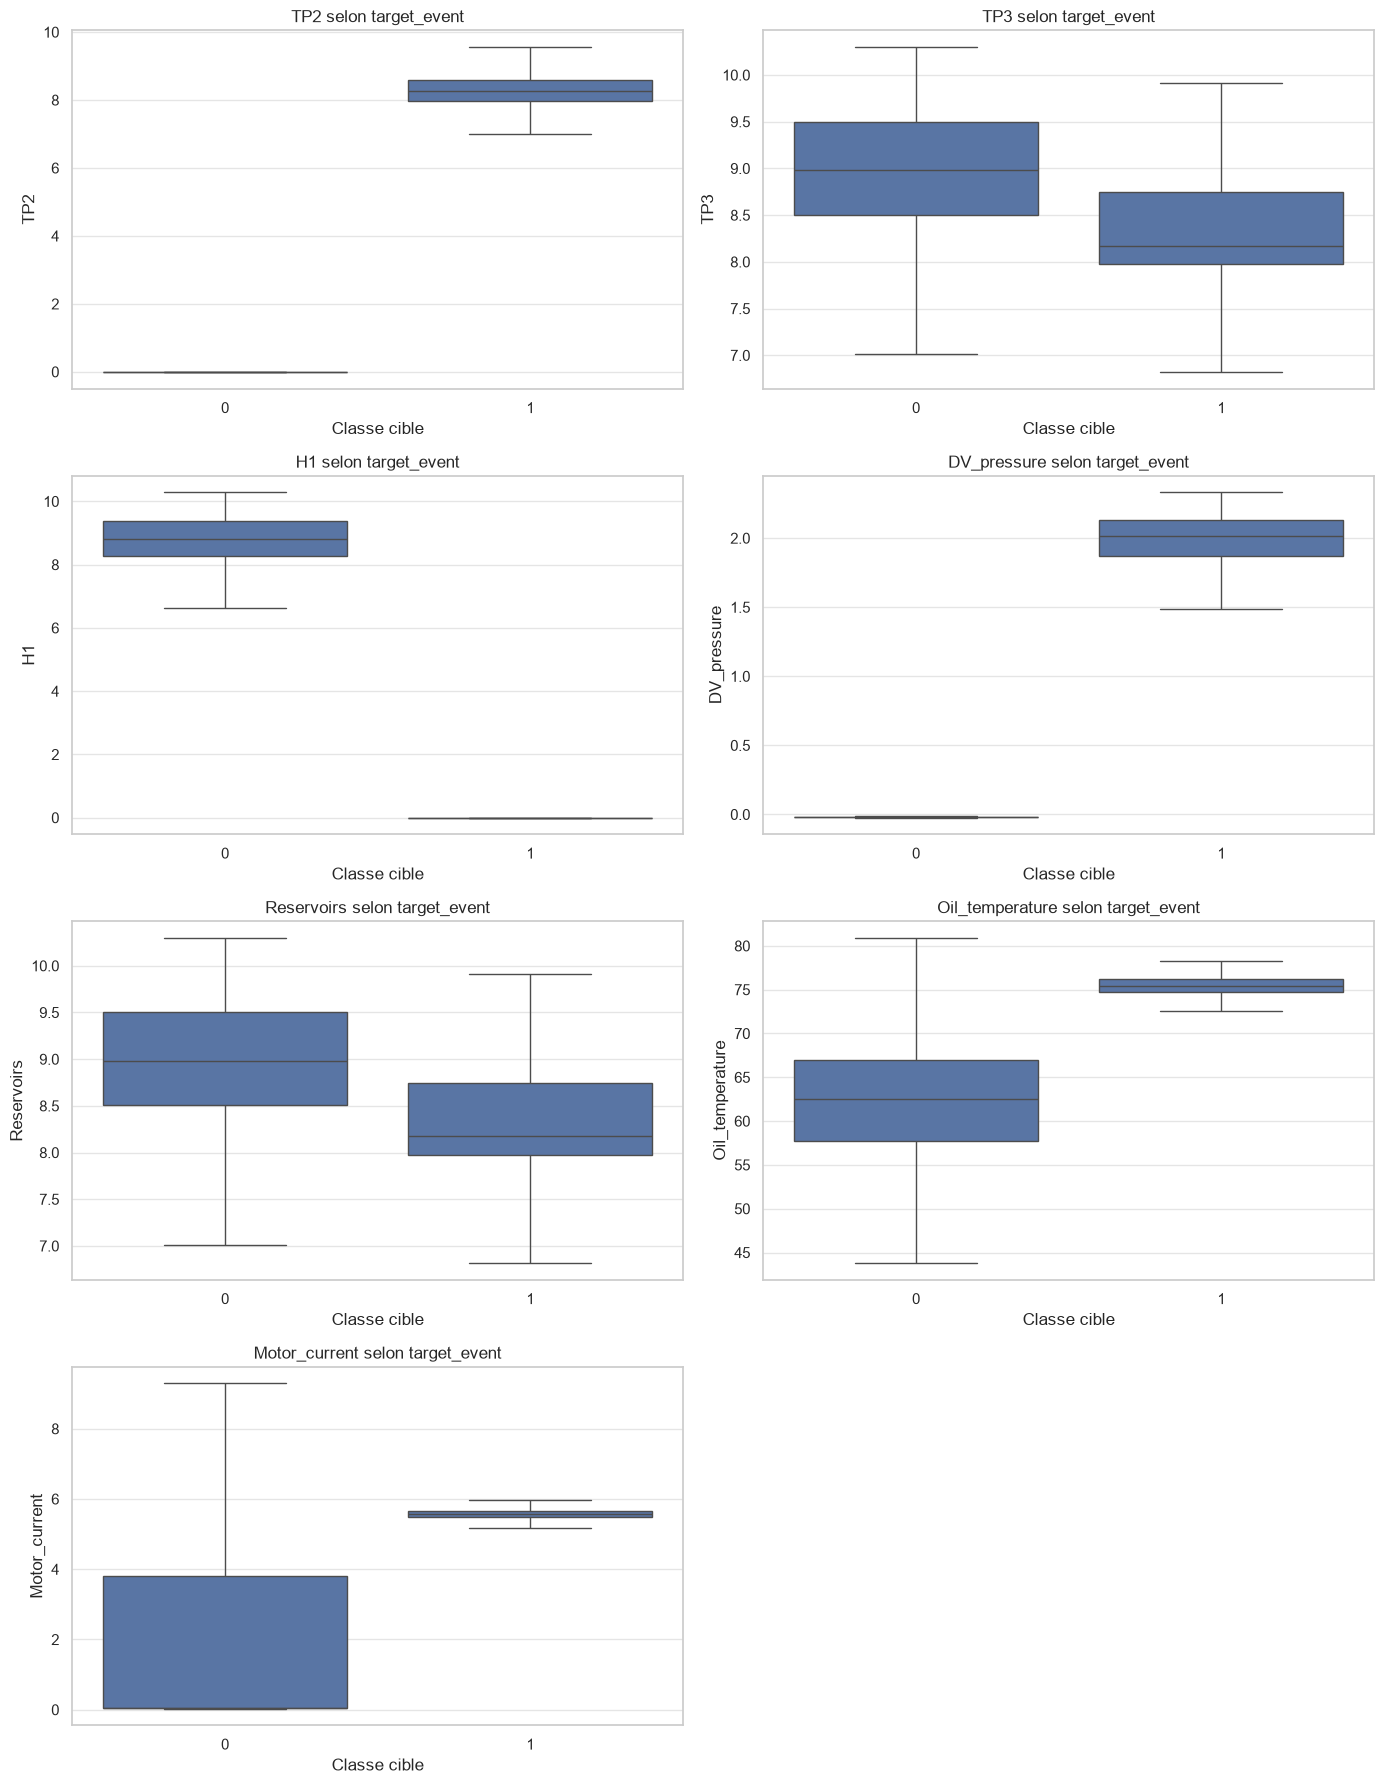

In [55]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(14, 18)
)

axes = axes.flatten()

for i, variable in enumerate(variables_numeriques):

    sns.boxplot(
        data=df,
        x=cible,
        y=variable,
        showfliers=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{variable} selon {cible}"
    )

    axes[i].set_xlabel("Classe cible")
    axes[i].set_ylabel(variable)

# Supprimer le dernier emplacement inutilisé
fig.delaxes(axes[-1])

plt.tight_layout()

plt.savefig(
    DOSSIER_FIGURES / "05_numeric_features_by_target.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

H1	TP3 et Reservoirs : Pearson = 0,999993	Les deux capteurs mesurent des pressions très fortement liées dans le fonctionnement observé.	Redondance potentielle. Évaluer leur utilité avant toute suppression.
H2	COMP et MPG : concordance de 99,57 %	Les deux signaux décrivent des états très proches du fonctionnement du compresseur.	Leur information peut être partiellement redondante. Conserver les deux provisoirement.
H3	TP2 et TP3 : corrélation globale faible, mais forte dans certaines configurations	La relation entre les pressions dépend de l'état de fonctionnement du compresseur.	Une corrélation globale peut masquer des relations conditionnelles utiles.
H4	H1 et DV_pressure : relations variables selon les configurations	Les pressions liées aux phases de purge ne présentent pas une relation uniforme dans tous les états observés.	Étudier les interactions et les états de fonctionnement dans la modélisation.
H5	Motor_current et TP2 : Pearson global = 0,697	Le courant moteur et la pression TP2 présentent une relation globale, mais celle-ci varie selon l'état du compresseur.	Les deux variables peuvent apporter des informations complémentaires.

## Conclusion – Analyse bivariée et multivariée

L'analyse des relations entre les variables numériques, digitales et la cible a permis d'identifier plusieurs dépendances entre les signaux du compresseur.

Les résultats montrent notamment une très forte corrélation entre TP3 et Reservoirs, ainsi qu'une concordance importante entre COMP et MPG. Certaines relations entre variables numériques évoluent également selon les configurations de fonctionnement du compresseur.

Ces observations soulignent l'importance de prendre en compte les états opérationnels lors de l'analyse des données industrielles. Une analyse globale des corrélations ne suffit pas toujours à caractériser les relations entre les capteurs.

Aucune variable n'est supprimée à ce stade. Les décisions de sélection seront évaluées expérimentalement et comparées au modèle baseline selon le même protocole de validation.

Les résultats de ce notebook constituent une base pour poursuivre l'étude temporelle des signaux et mieux comprendre le comportement du compresseur avant, pendant et après les événements documentés.